# 05 - Feature Engineering

This notebook develops, validates, and compares additional features for Store Sales - Time Series Forecasting.

Completed:
- Stage 1: Feature Engineering Setup and frozen Phase 3 baseline.
- Stage 2: Date-aligned advanced sales lags, recursive LightGBM experiments, and experiment comparison.

Objectives:
1. Preserve the Phase 3 Global LightGBM baseline (B0).
2. Evaluate recent, extended-weekly, and annual-weekly sales lags.
3. Use the same three fixed validation folds and 16-day recursive horizon.
4. Compare E1-E4 against B0 using fold-level and pooled OOF RMSLE.
5. Save predictions, metrics, missing-rate diagnostics, and feature importance.

Leakage rule:
- Training features use only observations strictly before each target date.
- Recursive validation uses previous predictions, never actual validation sales.
- Validation actuals are read only after all 16 daily predictions have been generated.

Run the notebook from top to bottom. The E1-E4 experiments are executed sequentially.


In [67]:
from pathlib import Path
import json
import gc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
warnings.filterwarnings("default")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Seaborn:", sns.__version__)


Pandas: 3.1.1
NumPy: 2.5.4
Seaborn: 0.13.2


In [68]:
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (path for path in candidates if (path / "data" / "raw" / "train.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/raw/train.csv. Open this notebook from the project directory."
    )

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
VALIDATION_DIR = ROOT / "reports" / "validation"
FEATURE_DIR = ROOT / "reports" / "feature_engineering"
FEATURE_IMPORTANCE_DIR = FEATURE_DIR / "feature_importance"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_IMPORTANCE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Raw data:", RAW_DIR)
print("Processed data:", PROCESSED_DIR)
print("Validation reports:", VALIDATION_DIR)
print("Feature Engineering reports:", FEATURE_DIR)


Project root: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-
Raw data: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\data\raw
Processed data: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\data\processed
Validation reports: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\reports\validation
Feature Engineering reports: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\reports\feature_engineering


In [69]:
folders_to_inspect = [PROCESSED_DIR, VALIDATION_DIR]
artifact_rows = []
for folder in folders_to_inspect:
    print(f"\n{'=' * 60}")
    print("Folder:", folder)
    if not folder.exists():
        print("Folder does not exist.")
        continue
    for file_path in sorted(folder.rglob("*")):
        if file_path.is_file():
            size_kb = file_path.stat().st_size / 1024
            relative_path = file_path.relative_to(ROOT)
            artifact_rows.append(
                {"path": str(relative_path), "size_kb": round(size_kb, 2)}
            )
            print(relative_path, f"({size_kb:.2f} KB)")

artifact_inventory = pd.DataFrame(artifact_rows)
display(artifact_inventory)

required_validation_artifacts = [
    "validation_folds.csv",
    "baseline_model_comparison.csv",
    "lightgbm_run_config.json",
    "seasonal_naive_fold_metrics.csv",
    "seasonal_naive_oof_predictions.csv",
    "lightgbm_fold_metrics.csv",
    "lightgbm_oof_predictions.csv",
]
missing_validation_artifacts = [
    name for name in required_validation_artifacts
    if not (VALIDATION_DIR / name).is_file()
]
print("Missing required validation artifacts:", missing_validation_artifacts)
assert not missing_validation_artifacts, (
    "Required Phase 3 artifacts are missing. Inspect the inventory before proceeding."
)



Folder: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\data\processed
data\processed\test_processed.csv (3139.97 KB)
data\processed\train_processed.csv (348941.60 KB)
data\processed\transactions_history.csv (1597.78 KB)

Folder: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\reports\validation
reports\validation\baseline_model_comparison.csv (0.33 KB)
reports\validation\lightgbm_family_metrics.csv (2.49 KB)
reports\validation\lightgbm_feature_importance.csv (0.74 KB)
reports\validation\lightgbm_fold_metrics.csv (0.25 KB)
reports\validation\lightgbm_horizon_metrics.csv (0.79 KB)
reports\validation\lightgbm_oof_predictions.csv (5024.08 KB)
reports\validation\lightgbm_run_config.json (1.49 KB)
reports\validation\seasonal_naive_family_metrics.csv (2.48 KB)
reports\validation\seasonal_naive_fold_metrics.csv (0.25 KB)
reports\validation\seasonal_naive_horizon_metrics.csv (0.78 KB)
reports\validation\seasonal_naive_oof_predictions.csv (3930.63 KB)
reports\validation\seasonal_naive_summary_me

,path,size_kb
0,data\processed\test_processed.csv,3139.97
1,data\processed\train_processed.csv,348941.60
2,data\processed\transactions_history.csv,1597.78
3,reports\validation\baseline_model_comparison.csv,0.33
4,reports\validation\lightgbm_family_metrics.csv,2.49
5,reports\validation\lightgbm_feature_importance...,0.74
6,reports\validation\lightgbm_fold_metrics.csv,0.25
7,reports\validation\lightgbm_horizon_metrics.csv,0.79
8,reports\validation\lightgbm_oof_predictions.csv,5024.08
9,reports\validation\lightgbm_run_config.json,1.49


Missing required validation artifacts: []


In [70]:
train = pd.read_csv(
    RAW_DIR / "train.csv",
    parse_dates=["date"],
    low_memory=False,
)
test = pd.read_csv(
    RAW_DIR / "test.csv",
    parse_dates=["date"],
    low_memory=False,
)
stores = pd.read_csv(RAW_DIR / "stores.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Stores shape:", stores.shape)
display(train.head())
display(test.head())
display(stores.head())


Train shape: (3000888, 6)
Test shape: (28512, 5)
Stores shape: (54, 5)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [71]:
print("Train date range:", train.date.min(), "->", train.date.max())
print("Test date range:", test.date.min(), "->", test.date.max())
print("Number of stores:", train.store_nbr.nunique())
print("Number of families:", train.family.nunique())
print(
    "Number of Store-Family series:",
    train[["store_nbr", "family"]].drop_duplicates().shape[0],
)
print(
    "Train duplicate keys:",
    int(train.duplicated(["date", "store_nbr", "family"]).sum()),
)
print(
    "Test duplicate keys:",
    int(test.duplicated(["date", "store_nbr", "family"]).sum()),
)

assert train.shape == (3_000_888, 6)
assert test.shape == (28_512, 5)
assert stores.shape[0] == 54
assert train.store_nbr.nunique() == 54
assert train.family.nunique() == 33
assert train[["store_nbr", "family"]].drop_duplicates().shape[0] == 1_782
assert train.date.min() == pd.Timestamp("2013-01-01")
assert train.date.max() == pd.Timestamp("2017-08-15")
assert test.date.min() == pd.Timestamp("2017-08-16")
assert test.date.max() == pd.Timestamp("2017-08-31")
assert not train.duplicated(["date", "store_nbr", "family"]).any()
assert not test.duplicated(["date", "store_nbr", "family"]).any()


Train date range: 2013-01-01 00:00:00 -> 2017-08-15 00:00:00
Test date range: 2017-08-16 00:00:00 -> 2017-08-31 00:00:00
Number of stores: 54
Number of families: 33
Number of Store-Family series: 1782
Train duplicate keys: 0
Test duplicate keys: 0


## Freeze the Phase 3 baseline results

These values are the recorded Phase 3 results, not scores recalculated in this notebook. Keep them unchanged as the reference for every Phase 4 experiment.


In [72]:
baseline_reference = pd.DataFrame(
    [
        {
            "model": "Seasonal Naive",
            "fold_1": 0.588248,
            "fold_2": 0.511097,
            "fold_3": 0.617040,
            "mean_fold_rmsle": 0.572128,
            "pooled_oof_rmsle": 0.573874,
        },
        {
            "model": "Global LightGBM",
            "fold_1": 0.569795,
            "fold_2": 0.390734,
            "fold_3": 0.437078,
            "mean_fold_rmsle": 0.465869,
            "pooled_oof_rmsle": 0.472009,
        },
    ]
)
display(baseline_reference)
baseline_reference.to_csv(FEATURE_DIR / "baseline_reference.csv", index=False)


,model,fold_1,fold_2,fold_3,mean_fold_rmsle,pooled_oof_rmsle
0,Seasonal Naive,0.588248,0.511097,0.617040,0.572128,0.573874
1,Global LightGBM,0.569795,0.390734,0.437078,0.465869,0.472009


In [73]:
BASELINE_FEATURE_CONFIG = {
    "lag_days": [7, 14, 21, 28],
    "rolling_windows": [7, 28],
    "calendar_features": ["dayofweek", "month", "day", "is_weekend"],
    "promotion_features": ["onpromotion"],
    "categorical_features": [
        "store_nbr", "family", "city", "state", "type", "cluster"
    ],
    "excluded_features": ["transactions", "oil", "holidays"],
}
baseline_config_path = VALIDATION_DIR / "lightgbm_run_config.json"
with baseline_config_path.open("r", encoding="utf-8") as file:
    baseline_run_config = json.load(file)

expected_feature_list = (
    [f"lag_{days}" for days in BASELINE_FEATURE_CONFIG["lag_days"]]
    + [
        f"rolling_mean_{days}"
        for days in BASELINE_FEATURE_CONFIG["rolling_windows"]
    ]
    + BASELINE_FEATURE_CONFIG["calendar_features"]
    + BASELINE_FEATURE_CONFIG["promotion_features"]
    + BASELINE_FEATURE_CONFIG["categorical_features"]
)
config_comparison = {
    "feature_list_matches": baseline_run_config["features"] == expected_feature_list,
    "lag_days_match": baseline_run_config["lag_days"] == BASELINE_FEATURE_CONFIG["lag_days"],
    "rolling_windows_match": baseline_run_config["rolling_windows_calendar_days"]
    == BASELINE_FEATURE_CONFIG["rolling_windows"],
    "excluded_features_match": baseline_run_config["excluded_features"]
    == BASELINE_FEATURE_CONFIG["excluded_features"],
    "target_transform_is_log1p": baseline_run_config["target_transform"] == "log1p(sales)",
    "recursive_validation_enabled": baseline_run_config["recursive_validation"] is True,
    "validation_actuals_excluded_from_features": baseline_run_config[
        "validation_actuals_used_for_features"
    ] is False,
}
config_comparison_df = pd.DataFrame(
    [{"check": key, "passed": value} for key, value in config_comparison.items()]
)
display(config_comparison_df)
print("Recorded LightGBM parameters:", baseline_run_config["parameters"])
assert all(config_comparison.values()), (
    "The Phase 3 baseline configuration differs from the documented B0 feature set."
)


,check,passed
0,feature_list_matches,True
1,lag_days_match,True
2,rolling_windows_match,True
3,excluded_features_match,True
4,target_transform_is_log1p,True
5,recursive_validation_enabled,True
6,validation_actuals_excluded_from_features,True


Recorded LightGBM parameters: {'objective': 'regression', 'n_estimators': 500, 'learning_rate': 0.05, 'num_leaves': 31, 'max_depth': -1, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'random_state': 42, 'n_jobs': -1, 'verbosity': -1}


In [74]:
experiment_log = pd.DataFrame(
    [
        {
            "experiment": "B0",
            "model": "Global LightGBM",
            "feature_group": "Baseline",
            "description": "Original Phase 3 Global LightGBM feature set",
            "fold_1_rmsle": 0.569795,
            "fold_2_rmsle": 0.390734,
            "fold_3_rmsle": 0.437078,
            "mean_fold_rmsle": 0.465869,
            "pooled_oof_rmsle": 0.472009,
            "status": "Frozen reference",
        }
    ]
)
display(experiment_log)
experiment_log.to_csv(FEATURE_DIR / "experiment_results.csv", index=False)
print("Stage 1 reference artifacts saved to:", FEATURE_DIR)


,experiment,model,feature_group,description,fold_1_rmsle,fold_2_rmsle,fold_3_rmsle,mean_fold_rmsle,pooled_oof_rmsle,status
0,B0,Global LightGBM,Baseline,Original Phase 3 Global LightGBM feature set,0.569795,0.390734,0.437078,0.465869,0.472009,Frozen reference


Stage 1 reference artifacts saved to: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\reports\feature_engineering


## Stage 1 checkpoint

After you run Cells 1-9, verify that:
- The input shapes, date ranges, series count, and duplicate checks pass.
- The Phase 3 validation artifacts are found; the inventory reports whether `data/processed/` exists.
- Every baseline configuration check passes against `lightgbm_run_config.json`.
- `baseline_reference.csv` and `experiment_results.csv` are written under `reports/feature_engineering/`.

No new features or models are introduced in Stage 1. Review these checks before starting Stage 2 (advanced sales lags).


# Stage 2 - Advanced Sales Lag Features

This stage adds date-aligned historical sales lags beyond the frozen B0 baseline.

B0 lags: `lag_7`, `lag_14`, `lag_21`, and `lag_28`.

E1 tests the recent lags `lag_1`, `lag_2`, `lag_3`, and `lag_5`. Later experiments can test extended weekly lags and `lag_364` separately.

All lag values are matched by exact calendar date. Missing source dates remain `NaN`. Validation uses the three fixed folds, a 16-day horizon, recursive forecasts, and no actual validation sales in future features.

This section builds and diagnoses features only. Model training is intentionally deferred until the feature builder has been reviewed.


In [75]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)

# Reuse the saved Phase 3 configuration and validation folds.
LGBM_PARAMS = baseline_run_config["parameters"].copy()
BASELINE_LAG_DAYS = BASELINE_FEATURE_CONFIG["lag_days"]
ROLLING_WINDOWS = BASELINE_FEATURE_CONFIG["rolling_windows"]
BASELINE_FEATURE_COLUMNS = baseline_run_config["features"]
CATEGORICAL_FEATURES = BASELINE_FEATURE_CONFIG["categorical_features"]

FOLDS = []
for saved_fold in baseline_run_config["folds"]:
    fold = saved_fold.copy()
    for column in ["train_end", "valid_start", "valid_end"]:
        fold[column] = pd.Timestamp(fold[column])
    FOLDS.append(fold)

FOLD_DAYS = 16
N_SERIES = train[["store_nbr", "family"]].drop_duplicates().shape[0]
EXTRA_LAGS = [1, 2, 3, 5]
ACTIVE_LAG_DAYS = sorted(set(BASELINE_LAG_DAYS + EXTRA_LAGS))
EXPERIMENT_NAME = "E1_recent_lags"
EXPERIMENT_FEATURE_COLUMNS = BASELINE_FEATURE_COLUMNS + [
    f"lag_{lag}" for lag in EXTRA_LAGS
]

print("Baseline lags:", BASELINE_LAG_DAYS)
print("Additional lags:", EXTRA_LAGS)
print("Active lags:", ACTIVE_LAG_DAYS)
print("Feature count:", len(EXPERIMENT_FEATURE_COLUMNS))
print("Number of series:", N_SERIES)
print("Validation folds:", [fold["fold"] for fold in FOLDS])
assert N_SERIES == 1782
assert len(EXPERIMENT_FEATURE_COLUMNS) == len(set(EXPERIMENT_FEATURE_COLUMNS))
assert all(f"lag_{lag}" in EXPERIMENT_FEATURE_COLUMNS for lag in ACTIVE_LAG_DAYS)


LightGBM version: 4.7.0
Baseline lags: [7, 14, 21, 28]
Additional lags: [1, 2, 3, 5]
Active lags: [1, 2, 3, 5, 7, 14, 21, 28]
Feature count: 21
Number of series: 1782
Validation folds: ['fold_1', 'fold_2', 'fold_3']


## 2.1. Date-aligned lag feature construction

For target date `t`, `lag_k` is read from the exact source date `t - k calendar days`, matching on date, store, and family. This keeps a missing date from shifting lag values to another observation.


In [76]:
def build_feature_rows_with_lags(
    history,
    target_rows,
    store_metadata,
    lag_days,
    rolling_windows,
):
    """Build leakage-safe calendar-aligned lags and prior rolling means.

    `target_rows` may contain sales; that column is deliberately ignored.
    `history` must contain only observations available at the forecast origin
    plus any previously generated predictions for recursive forecasting.
    """
    keys = ["store_nbr", "family"]
    required_history = {"date", "store_nbr", "family", "sales"}
    required_target = {"date", "store_nbr", "family", "onpromotion"}
    missing_history = required_history.difference(history.columns)
    missing_target = required_target.difference(target_rows.columns)
    if missing_history:
        raise ValueError(f"history is missing columns: {sorted(missing_history)}")
    if missing_target:
        raise ValueError(f"target_rows is missing columns: {sorted(missing_target)}")
    if history.duplicated(["date", *keys]).any():
        raise ValueError("history contains duplicate date/store/family keys.")
    if target_rows.duplicated(["date", *keys]).any():
        raise ValueError("target_rows contains duplicate date/store/family keys.")

    base = target_rows[["date", *keys, "onpromotion"]].copy()
    base["_feature_row_order"] = np.arange(len(base))
    base["dayofweek"] = base.date.dt.day_of_week.astype("int8")
    base["month"] = base.date.dt.month.astype("int8")
    base["day"] = base.date.dt.day.astype("int8")
    base["is_weekend"] = base.dayofweek.isin([5, 6]).astype("int8")

    history_lookup = history[["date", *keys, "sales"]].copy()
    for lag in sorted(set(lag_days)):
        lag_lookup = history_lookup.copy()
        lag_lookup["date"] = lag_lookup.date + pd.Timedelta(days=int(lag))
        lag_lookup = lag_lookup.rename(columns={"sales": f"lag_{lag}"})
        base = base.merge(
            lag_lookup,
            on=["date", *keys],
            how="left",
            validate="one_to_one",
        )

    if base.date.nunique() == 1:
        target_date = base.date.iloc[0]
        for window in rolling_windows:
            window_history = history.loc[
                history.date.ge(target_date - pd.Timedelta(days=int(window)))
                & history.date.lt(target_date)
            ]
            rolling = (
                window_history.groupby(keys, as_index=False).sales.mean()
                .rename(columns={"sales": f"rolling_mean_{window}"})
            )
            base = base.merge(
                rolling,
                on=keys,
                how="left",
                validate="one_to_one",
            )
    else:
        rolling_parts = []
        for (store_nbr, family), group in history.groupby(keys, sort=False):
            sales_by_date = group.sort_values("date").set_index("date")["sales"]
            part = pd.DataFrame({"date": sales_by_date.index})
            for window in rolling_windows:
                part[f"rolling_mean_{window}"] = (
                    sales_by_date.rolling(
                        f"{int(window)}D", closed="left", min_periods=1
                    ).mean().to_numpy()
                )
            part["store_nbr"] = store_nbr
            part["family"] = family
            rolling_parts.append(part)
        if rolling_parts:
            rolling_features = pd.concat(rolling_parts, ignore_index=True)
            base = base.merge(
                rolling_features,
                on=["date", *keys],
                how="left",
                validate="one_to_one",
            )
        else:
            for window in rolling_windows:
                base[f"rolling_mean_{window}"] = np.nan

    base = base.merge(
        store_metadata[["store_nbr", "city", "state", "type", "cluster"]],
        on="store_nbr",
        how="left",
        validate="many_to_one",
    )
    base = base.sort_values("_feature_row_order").drop(
        columns="_feature_row_order"
    )
    return base.reset_index(drop=True)


In [77]:
def prepare_model_matrix(
    feature_frame,
    feature_columns,
    categorical_features,
    category_levels=None,
):
    """Select model features and align categorical levels across datasets."""
    missing_columns = [
        column for column in feature_columns
        if column not in feature_frame.columns
    ]
    if missing_columns:
        raise ValueError(f"Missing model features: {missing_columns}")

    matrix = feature_frame[feature_columns].copy()
    if category_levels is None:
        category_levels = {
            column: pd.Index(matrix[column].dropna().unique()).sort_values()
            for column in categorical_features
        }
    for column in categorical_features:
        matrix[column] = pd.Categorical(
            matrix[column], categories=category_levels[column]
        )
    return matrix, category_levels


In [78]:
store_metadata = stores[["store_nbr", "city", "state", "type", "cluster"]].copy()
PROBE_DATE = pd.Timestamp("2017-08-15")
probe_target = train.loc[
    train.date.eq(PROBE_DATE),
    ["date", "store_nbr", "family", "onpromotion"],
].head(1).copy()
probe_history = train.loc[
    train.date.lt(PROBE_DATE),
    ["date", "store_nbr", "family", "sales"],
].copy()
probe_features = build_feature_rows_with_lags(
    history=probe_history,
    target_rows=probe_target,
    store_metadata=store_metadata,
    lag_days=ACTIVE_LAG_DAYS,
    rolling_windows=ROLLING_WINDOWS,
)
display(
    probe_features[
        ["date", "store_nbr", "family"]
        + [f"lag_{lag}" for lag in ACTIVE_LAG_DAYS]
    ]
)


,date,store_nbr,family,lag_1,lag_2,lag_3,lag_5,lag_7,lag_14,lag_21,lag_28
0,2017-08-15,1,AUTOMOTIVE,1.0,1.0,6.0,9.0,4.0,5.0,10.0,3.0


In [79]:
probe_matrix, probe_category_levels = prepare_model_matrix(
    feature_frame=probe_features,
    feature_columns=EXPERIMENT_FEATURE_COLUMNS,
    categorical_features=CATEGORICAL_FEATURES
)

print("Model matrix shape:", probe_matrix.shape)

print("\nCategorical dtypes:")
display(probe_matrix[CATEGORICAL_FEATURES].dtypes)

assert probe_matrix.columns.tolist() == EXPERIMENT_FEATURE_COLUMNS

assert all(
    isinstance(probe_matrix[column].dtype, pd.CategoricalDtype)
    for column in CATEGORICAL_FEATURES
)

print("prepare_model_matrix check passed.")

Model matrix shape: (1, 21)

Categorical dtypes:


store_nbr    category
family       category
city         category
state        category
type         category
cluster      category
dtype: object

prepare_model_matrix check passed.


In [80]:
probe_row = probe_target.iloc[0]
lag_check_results = []
for lag in ACTIVE_LAG_DAYS:
    source_date = PROBE_DATE - pd.Timedelta(days=lag)
    expected = probe_history.loc[
        probe_history.date.eq(source_date)
        & probe_history.store_nbr.eq(probe_row.store_nbr)
        & probe_history.family.eq(probe_row.family),
        "sales",
    ]
    actual = probe_features.iloc[0][f"lag_{lag}"]
    assert len(expected) == 1, (
        f"Expected source row for lag {lag} was not found."
    )
    assert np.isclose(actual, expected.iloc[0]), (
        f"Incorrect lag_{lag} value."
    )
    lag_check_results.append(
        {
            "lag": lag,
            "source_date": source_date,
            "expected_sales": expected.iloc[0],
            "feature_value": actual,
            "passed": True,
        }
    )
lag_check_df = pd.DataFrame(lag_check_results)
display(lag_check_df)
assert lag_check_df.passed.all()


,lag,source_date,expected_sales,feature_value,passed
0,1,2017-08-14,1.0,1.0,True
1,2,2017-08-13,1.0,1.0,True
2,3,2017-08-12,6.0,6.0,True
3,5,2017-08-10,9.0,9.0,True
4,7,2017-08-08,4.0,4.0,True
5,14,2017-08-01,5.0,5.0,True
6,21,2017-07-25,10.0,10.0,True
7,28,2017-07-18,3.0,3.0,True


In [81]:
CHRISTMAS_TARGET_DATE = pd.Timestamp("2013-12-26")
christmas_target = train.loc[
    train.date.eq(CHRISTMAS_TARGET_DATE),
    ["date", "store_nbr", "family", "onpromotion"],
].copy()
christmas_history = train.loc[
    train.date.lt(CHRISTMAS_TARGET_DATE),
    ["date", "store_nbr", "family", "sales"],
].copy()
christmas_features = build_feature_rows_with_lags(
    history=christmas_history,
    target_rows=christmas_target,
    store_metadata=store_metadata,
    lag_days=ACTIVE_LAG_DAYS,
    rolling_windows=ROLLING_WINDOWS,
)
print("Target rows:", len(christmas_features))
print("Missing lag_1:", int(christmas_features.lag_1.isna().sum()))
print("Missing lag_2:", int(christmas_features.lag_2.isna().sum()))
assert len(christmas_features) == N_SERIES
assert christmas_features.lag_1.isna().all()
assert christmas_features.lag_2.notna().all()


Target rows: 1782
Missing lag_1: 1782
Missing lag_2: 0


### Multi-date training feature path

The multi-date branch is used to create features for historical training rows. It uses calendar windows ending before each target date (`closed="left"`). Recursive validation still builds features one date at a time and adds only the preceding predictions to history.


In [82]:
diagnostic_dates = pd.date_range("2017-08-13", "2017-08-15", freq="D")
diagnostic_target = train.loc[
    train.date.isin(diagnostic_dates),
    ["date", "store_nbr", "family", "onpromotion"],
].copy()
diagnostic_history = train.loc[
    train.date.le(diagnostic_dates.max()),
    ["date", "store_nbr", "family", "sales"],
].copy()
diagnostic_features = build_feature_rows_with_lags(
    history=diagnostic_history,
    target_rows=diagnostic_target,
    store_metadata=store_metadata,
    lag_days=ACTIVE_LAG_DAYS,
    rolling_windows=ROLLING_WINDOWS,
)
expected_rows = len(diagnostic_dates) * N_SERIES
print("Expected rows:", expected_rows)
print("Actual rows:", len(diagnostic_features))
assert len(diagnostic_features) == expected_rows
assert not diagnostic_features.duplicated(
    ["date", "store_nbr", "family"]
).any()
assert diagnostic_features[
    [f"lag_{lag}" for lag in ACTIVE_LAG_DAYS]
].shape[1] == len(ACTIVE_LAG_DAYS)
assert "sales" not in diagnostic_features.columns


Expected rows: 5346
Actual rows: 5346


## 2.2. Lag feature missing analysis

Missing lag values are retained as `NaN`; they are not replaced with zero. This sample summarizes missing rates for the E1 lags while checking that the feature builder preserves missing source dates.


In [83]:
sample_dates = pd.date_range("2017-07-01", "2017-07-15", freq="D")
sample_targets = train.loc[
    train.date.isin(sample_dates),
    ["date", "store_nbr", "family", "onpromotion"],
].copy()
sample_history = train.loc[
    train.date.le(sample_dates.max()),
    ["date", "store_nbr", "family", "sales"],
].copy()
sample_features = build_feature_rows_with_lags(
    history=sample_history,
    target_rows=sample_targets,
    store_metadata=store_metadata,
    lag_days=ACTIVE_LAG_DAYS,
    rolling_windows=ROLLING_WINDOWS,
)
missing_report = pd.DataFrame(
    {
        "feature": [f"lag_{lag}" for lag in ACTIVE_LAG_DAYS],
        "missing_count": [
            int(sample_features[f"lag_{lag}"].isna().sum())
            for lag in ACTIVE_LAG_DAYS
        ],
        "missing_rate": [
            float(sample_features[f"lag_{lag}"].isna().mean())
            for lag in ACTIVE_LAG_DAYS
        ],
    }
)
display(missing_report)
missing_report.to_csv(
    FEATURE_DIR / "E1_recent_lag_missing_sample.csv", index=False
)


,feature,missing_count,missing_rate
0,lag_1,0,0.0
1,lag_2,0,0.0
2,lag_3,0,0.0
3,lag_5,0,0.0
4,lag_7,0,0.0
5,lag_14,0,0.0
6,lag_21,0,0.0
7,lag_28,0,0.0


## Stage 2 checkpoint - feature construction

The date-aligned feature builder, categorical model matrix, Christmas missing-date case, multi-date path, and lag missingness checks have been implemented.

The cells below evaluate E1-E4 using the same Global LightGBM parameters, fixed validation folds, 16-day recursive forecast horizon, and RMSLE metric as Phase 3.

Run experiments sequentially. Each experiment writes its own reports and does not overwrite the frozen B0 reference.


## 2.3. Model Matrix Validation

Verify that E1 features can be converted into a LightGBM-compatible matrix. Learn category levels from the training feature matrix and reuse them for recursive predictions.


In [84]:
probe_matrix, probe_category_levels = prepare_model_matrix(
    feature_frame=probe_features,
    feature_columns=EXPERIMENT_FEATURE_COLUMNS,
    categorical_features=CATEGORICAL_FEATURES,
)
print("Model matrix shape:", probe_matrix.shape)
print("Expected feature count:", len(EXPERIMENT_FEATURE_COLUMNS))
print("Categorical dtypes:")
display(probe_matrix[CATEGORICAL_FEATURES].dtypes)
assert probe_matrix.columns.tolist() == EXPERIMENT_FEATURE_COLUMNS
assert all(
    isinstance(probe_matrix[column].dtype, pd.CategoricalDtype)
    for column in CATEGORICAL_FEATURES
)
print("prepare_model_matrix check passed.")


Model matrix shape: (1, 21)
Expected feature count: 21
Categorical dtypes:


store_nbr    category
family       category
city         category
state        category
type         category
cluster      category
dtype: object

prepare_model_matrix check passed.


In [85]:
def rmsle(y_true, y_pred):
    """Compute RMSLE with input validation and non-negative predictions."""
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    if y_true.shape != y_pred.shape:
        raise ValueError("y_true and y_pred must have the same shape.")
    if not np.isfinite(y_true).all():
        raise ValueError("y_true contains NaN or infinity.")
    if not np.isfinite(y_pred).all():
        raise ValueError("y_pred contains NaN or infinity.")
    if (y_true < 0).any():
        raise ValueError("y_true must be non-negative.")
    y_pred = np.clip(y_pred, 0, None)
    log_error = np.log1p(y_pred) - np.log1p(y_true)
    return float(np.sqrt(np.mean(log_error ** 2)))


test_score = rmsle(
    np.array([0, 10, 100, 1000]),
    np.array([0, 12, 90, 1100]),
)
print("RMSLE test:", test_score)
assert np.isfinite(test_score) and test_score >= 0


RMSLE test: 0.10936652995958641


## 3. Recursive LightGBM Lag Experiments

A shared experiment runner supports E1, E2, E3, and E4. Each run keeps the Phase 3 model parameters, target transform, rolling windows, categorical features, and fixed folds. It generates all 16 validation predictions recursively before reading validation actual sales for scoring.

Run one experiment at a time. Start with E1 and review its fold, family, horizon, missing-rate, and feature-importance results before proceeding to E2 or E3.


In [88]:
def run_lag_experiment(extra_lags, experiment_name):
    """Train and evaluate one recursive Global LightGBM lag experiment.

    Validation targets are read only after all recursive forecasts for a fold
    have been generated. Reports are saved with an experiment-specific prefix.
    """
    extra_lags = sorted(set(int(lag) for lag in extra_lags))
    if not extra_lags:
        raise ValueError("extra_lags must not be empty.")
    if any(lag <= 0 for lag in extra_lags):
        raise ValueError("All lags must be positive.")
    if not experiment_name or Path(experiment_name).name != experiment_name:
        raise ValueError("experiment_name must be a non-empty file-name prefix.")

    active_lags = sorted(set(BASELINE_LAG_DAYS + extra_lags))
    feature_columns = BASELINE_FEATURE_COLUMNS + [
        f"lag_{lag}" for lag in extra_lags
    ]
    if len(feature_columns) != len(set(feature_columns)):
        raise ValueError("Experiment feature list contains duplicates.")

    fold_metrics = []
    fold_prediction_parts = []
    importance_parts = []
    missing_parts = []

    for fold in FOLDS:
        print(f"\nRunning {experiment_name} on {fold['fold']}...")
        fold_train = train.loc[train.date.le(fold["train_end"])].copy()
        first_training_date = fold_train.date.min()
        training_rows = fold_train.loc[
            fold_train.date.ge(first_training_date + pd.Timedelta(days=28)),
            ["date", "store_nbr", "family", "onpromotion", "sales"],
        ].copy()
        history_columns = ["date", "store_nbr", "family", "sales"]
        train_history = fold_train[history_columns].copy()

        train_feature_frame = build_feature_rows_with_lags(
            history=train_history,
            target_rows=training_rows,
            store_metadata=store_metadata,
            lag_days=active_lags,
            rolling_windows=ROLLING_WINDOWS,
        )

        # Ensure feature rows and target labels have exactly the same order.
        feature_keys = ["date", "store_nbr", "family"]
        if not train_feature_frame[feature_keys].reset_index(drop=True).equals(
            training_rows[feature_keys].reset_index(drop=True)
        ):
            raise AssertionError(
                "Training feature rows are not aligned with target labels."
            )

        if "sales" in train_feature_frame.columns:
            raise AssertionError(
                "Target sales unexpectedly leaked into the feature frame."
            )

        for lag in extra_lags:
            values = train_feature_frame[f"lag_{lag}"]
            missing_parts.append(
                {
                    "experiment": experiment_name,
                    "fold": fold["fold"],
                    "feature": f"lag_{lag}",
                    "training_rows": len(train_feature_frame),
                    "missing_count": int(values.isna().sum()),
                    "missing_rate": float(values.isna().mean()),
                }
            )

        X_train, category_levels = prepare_model_matrix(
            feature_frame=train_feature_frame,
            feature_columns=feature_columns,
            categorical_features=CATEGORICAL_FEATURES,
        )
        y_train = np.log1p(training_rows.sales.to_numpy(dtype=np.float64))
        model = lgb.LGBMRegressor(**LGBM_PARAMS)
        model.fit(X_train, y_train, categorical_feature=CATEGORICAL_FEATURES)

        recursive_history = train_history.copy()
        valid_dates = pd.date_range(
            fold["valid_start"], fold["valid_end"], freq="D"
        )
        fold_predictions = []
        for horizon, current_date in enumerate(valid_dates, start=1):
            # sales is intentionally excluded; promotion is known in advance.
            known_future = train.loc[
                train.date.eq(current_date),
                ["date", "store_nbr", "family", "onpromotion"],
            ].copy()
            current_feature_frame = build_feature_rows_with_lags(
                history=recursive_history,
                target_rows=known_future,
                store_metadata=store_metadata,
                lag_days=active_lags,
                rolling_windows=ROLLING_WINDOWS,
            )
            X_current, _ = prepare_model_matrix(
                feature_frame=current_feature_frame,
                feature_columns=feature_columns,
                categorical_features=CATEGORICAL_FEATURES,
                category_levels=category_levels,
            )
            predicted_log_sales = model.predict(X_current)
            if not np.isfinite(predicted_log_sales).all():
                raise ValueError(
                    f"Non-finite log predictions on {current_date:%Y-%m-%d}."
                )
            predicted_sales = np.clip(
                np.expm1(predicted_log_sales), 0, None
            )
            if not np.isfinite(predicted_sales).all():
                raise ValueError(
                    f"Non-finite sales predictions on {current_date:%Y-%m-%d}."
                )

            prediction_frame = known_future[
                ["date", "store_nbr", "family"]
            ].copy()
            prediction_frame["horizon"] = horizon
            prediction_frame["sales_pred"] = predicted_sales
            fold_predictions.append(prediction_frame)

            # Future history receives predictions only, never validation actuals.
            history_update = prediction_frame[
                ["date", "store_nbr", "family"]
            ].copy()
            history_update["sales"] = predicted_sales
            recursive_history = pd.concat(
                [recursive_history, history_update], ignore_index=True
            )

        predictions = pd.concat(fold_predictions, ignore_index=True)
        # Validation actuals are loaded only after recursive forecasting is done.
        valid_actual = train.loc[
            train.date.between(fold["valid_start"], fold["valid_end"]),
            ["date", "store_nbr", "family", "sales"],
        ].rename(columns={"sales": "sales_true"})
        evaluated = valid_actual.merge(
            predictions,
            on=["date", "store_nbr", "family"],
            how="inner",
            validate="one_to_one",
        )
        expected_rows = FOLD_DAYS * N_SERIES
        assert len(predictions) == expected_rows
        assert len(valid_actual) == expected_rows
        assert len(evaluated) == expected_rows

        fold_score = rmsle(evaluated.sales_true, evaluated.sales_pred)
        evaluated["experiment"] = experiment_name
        evaluated["fold"] = fold["fold"]
        fold_prediction_parts.append(evaluated)
        fold_metrics.append(
            {
                "experiment": experiment_name,
                "fold": fold["fold"],
                "train_end": fold["train_end"],
                "valid_start": fold["valid_start"],
                "valid_end": fold["valid_end"],
                "n_predictions": len(evaluated),
                "rmsle": fold_score,
            }
        )

        booster = model.booster_
        gains = booster.feature_importance(importance_type="gain")
        splits = booster.feature_importance(importance_type="split")
        gain_total = gains.sum()
        importance_parts.append(
            pd.DataFrame(
                {
                    "experiment": experiment_name,
                    "fold": fold["fold"],
                    "feature": booster.feature_name(),
                    "gain": gains,
                    "gain_share": gains / gain_total if gain_total > 0 else np.nan,
                    "split": splits,
                }
            )
        )
        print("Predictions:", len(evaluated), "RMSLE:", fold_score)

        del model, booster, X_train, train_feature_frame
        del recursive_history, fold_train, train_history
        gc.collect()

    fold_metrics_df = pd.DataFrame(fold_metrics)
    oof_predictions = pd.concat(fold_prediction_parts, ignore_index=True)
    oof_predictions["squared_log_error"] = (
        np.log1p(oof_predictions.sales_pred)
        - np.log1p(oof_predictions.sales_true)
    ) ** 2
    mean_fold_rmsle = float(fold_metrics_df.rmsle.mean())
    pooled_oof_rmsle = rmsle(
        oof_predictions.sales_true, oof_predictions.sales_pred
    )

    horizon_summary = (
        oof_predictions.groupby("horizon")
        .agg(
            mean_squared_log_error=("squared_log_error", "mean"),
            n_predictions=("sales_true", "size"),
        )
        .reset_index()
    )
    horizon_summary["rmsle"] = np.sqrt(
        horizon_summary.mean_squared_log_error
    )
    family_summary = (
        oof_predictions.groupby("family")
        .agg(
            mean_squared_log_error=("squared_log_error", "mean"),
            n_predictions=("sales_true", "size"),
            mean_actual_sales=("sales_true", "mean"),
        )
        .reset_index()
    )
    family_summary["rmsle"] = np.sqrt(
        family_summary.mean_squared_log_error
    )
    family_summary = family_summary.sort_values("rmsle", ascending=False)

    importance_by_fold = pd.concat(importance_parts, ignore_index=True)
    importance_summary = (
        importance_by_fold.groupby("feature", as_index=False)
        .agg(
            mean_gain=("gain", "mean"),
            mean_gain_share=("gain_share", "mean"),
            std_gain_share=("gain_share", "std"),
            mean_split=("split", "mean"),
        )
        .sort_values("mean_gain_share", ascending=False)
    )
    missing_summary = pd.DataFrame(missing_parts)

    # Save this experiment without overwriting the B0 reference row.
    prefix = experiment_name
    fold_metrics_df.to_csv(
        FEATURE_DIR / f"{prefix}_fold_metrics.csv", index=False
    )
    oof_predictions[
        [
            "experiment", "fold", "horizon", "date", "store_nbr",
            "family", "sales_true", "sales_pred",
        ]
    ].to_csv(FEATURE_DIR / f"{prefix}_oof_predictions.csv", index=False)
    horizon_summary.to_csv(
        FEATURE_DIR / f"{prefix}_horizon_metrics.csv", index=False
    )
    family_summary.to_csv(
        FEATURE_DIR / f"{prefix}_family_metrics.csv", index=False
    )
    missing_summary.to_csv(
        FEATURE_DIR / f"{prefix}_lag_missing_rates.csv", index=False
    )
    importance_by_fold.to_csv(
        FEATURE_IMPORTANCE_DIR / f"{prefix}_by_fold.csv", index=False
    )
    importance_summary.to_csv(
        FEATURE_IMPORTANCE_DIR / f"{prefix}_summary.csv", index=False
    )

    run_config = {
        "experiment": experiment_name,
        "baseline_lags": BASELINE_LAG_DAYS,
        "extra_lags": extra_lags,
        "active_lags": active_lags,
        "feature_columns": feature_columns,
        "rolling_windows_calendar_days": ROLLING_WINDOWS,
        "target_transform": "log1p(sales)",
        "inverse_transform": "expm1 clipped at zero",
        "recursive_forecasting": True,
        "validation_actuals_used_for_features": False,
        "parameters": LGBM_PARAMS,
        "folds": [
            {
                key: value.isoformat() if isinstance(value, pd.Timestamp) else value
                for key, value in fold.items()
            }
            for fold in FOLDS
        ],
    }
    with (FEATURE_DIR / f"{prefix}_run_config.json").open(
        "w", encoding="utf-8"
    ) as file:
        json.dump(run_config, file, indent=2)

    experiment_results_path = FEATURE_DIR / "experiment_results.csv"
    if experiment_results_path.exists():
        experiment_results = pd.read_csv(experiment_results_path)
    else:
        experiment_results = pd.DataFrame()
    if not experiment_results.empty and "experiment" in experiment_results:
        experiment_results = experiment_results.loc[
            experiment_results.experiment.ne(experiment_name)
        ]
    baseline_reference_table = pd.read_csv(
        FEATURE_DIR / "baseline_reference.csv"
    )
    baseline_row = baseline_reference_table.loc[
        baseline_reference_table["model"].eq("Global LightGBM")
    ]
    if len(baseline_row) != 1:
        raise ValueError(
            "Expected exactly one frozen Global LightGBM B0 reference row."
        )
    baseline_pooled_score = float(
        baseline_row["pooled_oof_rmsle"].iloc[0]
    )
    baseline_fold_scores = {
        "fold_1": float(baseline_row["fold_1"].iloc[0]),
        "fold_2": float(baseline_row["fold_2"].iloc[0]),
        "fold_3": float(baseline_row["fold_3"].iloc[0]),
    }

    fold_score_lookup = {
        f"fold_{index + 1}": float(
            fold_metrics_df.loc[
                fold_metrics_df.fold.eq(f"fold_{index + 1}"), "rmsle"
            ].iloc[0]
        )
        for index in range(len(fold_metrics_df))
    }

    result_row = {
        "experiment": experiment_name,
        "model": "Global LightGBM",
        "feature_group": ", ".join(f"lag_{lag}" for lag in extra_lags),
        "description": f"B0 plus {', '.join(f'lag_{lag}' for lag in extra_lags)}",
        "fold_1_rmsle": float(
            fold_metrics_df.loc[fold_metrics_df.fold.eq("fold_1"), "rmsle"].iloc[0]
        ),
        "fold_2_rmsle": float(
            fold_metrics_df.loc[fold_metrics_df.fold.eq("fold_2"), "rmsle"].iloc[0]
        ),
        "fold_3_rmsle": float(
            fold_metrics_df.loc[fold_metrics_df.fold.eq("fold_3"), "rmsle"].iloc[0]
        ),
        "mean_fold_rmsle": mean_fold_rmsle,
        "pooled_oof_rmsle": pooled_oof_rmsle,
        "pooled_improvement_pct_vs_B0": (
            (baseline_pooled_score - pooled_oof_rmsle)
            / baseline_pooled_score * 100
        ),
        "fold_1_improvement_pct_vs_B0": (
            (baseline_fold_scores["fold_1"] - fold_score_lookup["fold_1"])
            / baseline_fold_scores["fold_1"] * 100
        ),
        "fold_2_improvement_pct_vs_B0": (
            (baseline_fold_scores["fold_2"] - fold_score_lookup["fold_2"])
            / baseline_fold_scores["fold_2"] * 100
        ),
        "fold_3_improvement_pct_vs_B0": (
            (baseline_fold_scores["fold_3"] - fold_score_lookup["fold_3"])
            / baseline_fold_scores["fold_3"] * 100
        ),
        "status": "Completed",
    }
    experiment_results = pd.concat(
        [experiment_results, pd.DataFrame([result_row])], ignore_index=True
    )
    experiment_results.to_csv(experiment_results_path, index=False)

    return {
        "experiment": experiment_name,
        "fold_metrics": fold_metrics_df,
        "oof_predictions": oof_predictions,
        "mean_fold_rmsle": mean_fold_rmsle,
        "pooled_oof_rmsle": pooled_oof_rmsle,
        "horizon_summary": horizon_summary,
        "family_summary": family_summary,
        "missing_summary": missing_summary,
        "importance_by_fold": importance_by_fold,
        "importance_summary": importance_summary,
        "experiment_results": experiment_results,
    }


## Experiment E1 - Recent Sales Lags

E1 adds `lag_1`, `lag_2`, `lag_3`, and `lag_5` to B0. Run E1 by itself, then review its fold scores, missing rates, family/horizon errors, and normalized feature importance before deciding whether to proceed to E2 and E3.


In [89]:
E1 = run_lag_experiment(
    extra_lags=[1, 2, 3, 5],
    experiment_name="E1_recent_lags",
)
display(E1["fold_metrics"])
display(E1["missing_summary"])
display(E1["importance_summary"].head(15))
display(E1["horizon_summary"])
display(E1["family_summary"].head(15))
print("Mean Fold RMSLE:", E1["mean_fold_rmsle"])
print("Pooled OOF RMSLE:", E1["pooled_oof_rmsle"])



Running E1_recent_lags on fold_1...
Predictions: 28512 RMSLE: 0.46855639210833555

Running E1_recent_lags on fold_2...
Predictions: 28512 RMSLE: 0.38930576876685996

Running E1_recent_lags on fold_3...
Predictions: 28512 RMSLE: 0.42958439575706747


,experiment,fold,train_end,valid_start,valid_end,n_predictions,rmsle
0,E1_recent_lags,fold_1,2016-07-30,2016-07-31,2016-08-15,28512,0.468556
1,E1_recent_lags,fold_2,2017-06-30,2017-07-01,2017-07-16,28512,0.389306
2,E1_recent_lags,fold_3,2017-07-30,2017-07-31,2017-08-15,28512,0.429584


,experiment,fold,feature,training_rows,missing_count,missing_rate
0,E1_recent_lags,fold_1,lag_1,2273832,5346,0.002351
1,E1_recent_lags,fold_1,lag_2,2273832,5346,0.002351
2,E1_recent_lags,fold_1,lag_3,2273832,5346,0.002351
3,E1_recent_lags,fold_1,lag_5,2273832,5346,0.002351
4,E1_recent_lags,fold_2,lag_1,2869020,7128,0.002484
5,E1_recent_lags,fold_2,lag_2,2869020,7128,0.002484
6,E1_recent_lags,fold_2,lag_3,2869020,7128,0.002484
7,E1_recent_lags,fold_2,lag_5,2869020,7128,0.002484
8,E1_recent_lags,fold_3,lag_1,2922480,7128,0.002439
9,E1_recent_lags,fold_3,lag_2,2922480,7128,0.002439


,feature,mean_gain,mean_gain_share,std_gain_share,mean_split
13,lag_7,1.144787e+08,0.582002,0.010378,1084.666667
17,rolling_mean_7,5.107235e+07,0.257884,0.016007,1045.000000
6,lag_1,1.287067e+07,0.065841,0.005913,1335.000000
16,rolling_mean_28,1.238008e+07,0.062774,0.000819,676.666667
8,lag_2,1.773632e+06,0.008999,0.000056,629.000000
7,lag_14,1.709376e+06,0.008657,0.000312,581.333333
4,family,6.759957e+05,0.003480,0.000559,2168.333333
10,lag_28,4.502852e+05,0.002267,0.000213,514.666667
9,lag_21,4.087890e+05,0.002081,0.000067,412.000000
3,dayofweek,3.614625e+05,0.001883,0.000556,1226.333333


,horizon,mean_squared_log_error,n_predictions,rmsle
0,1,0.138747,5346,0.372487
1,2,0.217245,5346,0.466095
2,3,0.170120,5346,0.412456
3,4,0.163222,5346,0.404007
4,5,0.164963,5346,0.406156
5,6,0.166860,5346,0.408486
6,7,0.166332,5346,0.407838
7,8,0.163343,5346,0.404157
8,9,0.178325,5346,0.422285
9,10,0.171419,5346,0.414028


,family,mean_squared_log_error,n_predictions,mean_actual_sales,rmsle
31,SCHOOL AND OFFICE SUPPLIES,0.453337,2592,22.091049,0.673303
13,GROCERY II,0.451739,2592,26.229552,0.672115
21,LINGERIE,0.384100,2592,6.619985,0.619758
6,CELEBRATION,0.330468,2592,13.329090,0.574864
19,LADIESWEAR,0.300292,2592,11.115741,0.547989
14,HARDWARE,0.289882,2592,1.401235,0.538407
23,MAGAZINES,0.283267,2592,6.368056,0.532228
15,HOME AND KITCHEN I,0.280103,2592,31.070216,0.529247
22,"LIQUOR,WINE,BEER",0.271311,2592,97.552855,0.520875
0,AUTOMOTIVE,0.270275,2592,7.293210,0.519880


Mean Fold RMSLE: 0.42914885221075433
Pooled OOF RMSLE: 0.43036683083880156


In [90]:
# Recover E1 from its saved reports; this does not fit or train a model.
E1_NAME = "E1_recent_lags"
E1_PREFIX = FEATURE_DIR / E1_NAME

E1_fold_metrics = pd.read_csv(FEATURE_DIR / f"{E1_NAME}_fold_metrics.csv")
E1_oof_predictions = pd.read_csv(
    FEATURE_DIR / f"{E1_NAME}_oof_predictions.csv",
    parse_dates=["date"],
)
E1_oof_predictions["squared_log_error"] = (
    np.log1p(E1_oof_predictions["sales_pred"].clip(lower=0))
    - np.log1p(E1_oof_predictions["sales_true"].clip(lower=0))
) ** 2
E1_horizon_summary = pd.read_csv(
    FEATURE_DIR / f"{E1_NAME}_horizon_metrics.csv"
)
E1_family_summary = pd.read_csv(
    FEATURE_DIR / f"{E1_NAME}_family_metrics.csv"
)
E1_missing_summary = pd.read_csv(
    FEATURE_DIR / f"{E1_NAME}_lag_missing_rates.csv"
)
E1_importance_by_fold = pd.read_csv(
    FEATURE_IMPORTANCE_DIR / f"{E1_NAME}_by_fold.csv"
)
E1_importance_summary = pd.read_csv(
    FEATURE_IMPORTANCE_DIR / f"{E1_NAME}_summary.csv"
)

expected_E1_rows = 3 * 16 * 1782
if len(E1_oof_predictions) != expected_E1_rows:
    raise ValueError(
        f"Expected {expected_E1_rows:,} E1 OOF rows; "
        f"found {len(E1_oof_predictions):,}."
    )
if E1_oof_predictions.duplicated(
    ["fold", "date", "store_nbr", "family"]
).any():
    raise ValueError("E1 OOF predictions contain duplicate fold/date/series keys.")

E1_mean_fold_rmsle = float(E1_fold_metrics["rmsle"].mean())
E1_pooled_oof_rmsle = float(
    rmsle(E1_oof_predictions["sales_true"], E1_oof_predictions["sales_pred"])
)

baseline_reference_table = pd.read_csv(
    FEATURE_DIR / "baseline_reference.csv"
)
B0_reference = baseline_reference_table.loc[
    baseline_reference_table["model"].eq("Global LightGBM")
]
if len(B0_reference) != 1:
    raise ValueError("Expected exactly one Global LightGBM row in baseline_reference.csv.")
B0_reference = B0_reference.iloc[0]
B0_fold_scores = {
    f"fold_{index}": float(B0_reference[f"fold_{index}"])
    for index in (1, 2, 3)
}
E1_fold_scores = {
    str(row.fold): float(row.rmsle)
    for row in E1_fold_metrics.itertuples(index=False)
}

E1_result_row = {
    "experiment": E1_NAME,
    "model": "Global LightGBM",
    "feature_group": "lag_1, lag_2, lag_3, lag_5",
    "description": "B0 plus lag_1, lag_2, lag_3, lag_5",
    "fold_1_rmsle": E1_fold_scores["fold_1"],
    "fold_2_rmsle": E1_fold_scores["fold_2"],
    "fold_3_rmsle": E1_fold_scores["fold_3"],
    "mean_fold_rmsle": E1_mean_fold_rmsle,
    "pooled_oof_rmsle": E1_pooled_oof_rmsle,
    "pooled_improvement_pct_vs_B0": (
        (float(B0_reference["pooled_oof_rmsle"]) - E1_pooled_oof_rmsle)
        / float(B0_reference["pooled_oof_rmsle"]) * 100
    ),
    "fold_1_improvement_pct_vs_B0": (
        (B0_fold_scores["fold_1"] - E1_fold_scores["fold_1"])
        / B0_fold_scores["fold_1"] * 100
    ),
    "fold_2_improvement_pct_vs_B0": (
        (B0_fold_scores["fold_2"] - E1_fold_scores["fold_2"])
        / B0_fold_scores["fold_2"] * 100
    ),
    "fold_3_improvement_pct_vs_B0": (
        (B0_fold_scores["fold_3"] - E1_fold_scores["fold_3"])
        / B0_fold_scores["fold_3"] * 100
    ),
    "status": "Recovered from saved reports",
}
E1_log_path = FEATURE_DIR / "experiment_results.csv"
E1_experiment_log = pd.read_csv(E1_log_path)
E1_experiment_log = E1_experiment_log.loc[
    E1_experiment_log["experiment"].ne(E1_NAME)
]
E1_experiment_log = pd.concat(
    [E1_experiment_log, pd.DataFrame([E1_result_row])],
    ignore_index=True,
)
E1_experiment_log.to_csv(E1_log_path, index=False)

E1 = {
    "experiment": E1_NAME,
    "fold_metrics": E1_fold_metrics,
    "oof_predictions": E1_oof_predictions,
    "mean_fold_rmsle": E1_mean_fold_rmsle,
    "pooled_oof_rmsle": E1_pooled_oof_rmsle,
    "horizon_summary": E1_horizon_summary,
    "family_summary": E1_family_summary,
    "missing_summary": E1_missing_summary,
    "importance_by_fold": E1_importance_by_fold,
    "importance_summary": E1_importance_summary,
    "experiment_results": E1_experiment_log,
}

display(E1_experiment_log.loc[E1_experiment_log["experiment"].isin(["B0", E1_NAME])])
print("E1 restored from existing CSV reports; no model training was run.")


,experiment,model,feature_group,description,fold_1_rmsle,fold_2_rmsle,fold_3_rmsle,mean_fold_rmsle,pooled_oof_rmsle,status,pooled_improvement_pct_vs_B0,fold_1_improvement_pct_vs_B0,fold_2_improvement_pct_vs_B0,fold_3_improvement_pct_vs_B0
0,B0,Global LightGBM,Baseline,Original Phase 3 Global LightGBM feature set,0.569795,0.390734,0.437078,0.465869,0.472009,Frozen reference,NaN,NaN,NaN,NaN
1,E1_recent_lags,Global LightGBM,"lag_1, lag_2, lag_3, lag_5","B0 plus lag_1, lag_2, lag_3, lag_5",0.468556,0.389306,0.429584,0.429149,0.430367,Recovered from saved reports,8.822325,17.767549,0.365525,1.714478


E1 restored from existing CSV reports; no model training was run.


### E1 checkpoint

E1 adds `lag_1`, `lag_2`, `lag_3`, and `lag_5` to B0. Its recorded Pooled OOF RMSLE is approximately `0.430367`, compared with B0 at `0.472009`.

The remaining experiments below evaluate:
- E2: `lag_35`, `lag_42`, `lag_56`
- E3: `lag_364`
- E4: all candidate advanced lags together

The notebook runs each experiment sequentially. Review all fold scores and diagnostics before selecting a final lag set.


## Experiment E2 — Extended Weekly Lags

E2 adds `lag_35`, `lag_42`, and `lag_56` to the frozen B0 features.

Hypothesis: observations from the same weekday five, six, and eight weeks earlier may capture recurring weekly demand patterns beyond the four baseline weekly lags.

Missing source dates remain `NaN`; no zero imputation is applied.


In [91]:
E2 = run_lag_experiment(
    extra_lags=[35, 42, 56],
    experiment_name="E2_extended_weekly_lags",
)

display(E2["fold_metrics"])
display(E2["missing_summary"])
display(E2["importance_summary"].head(20))
display(E2["horizon_summary"])
display(E2["family_summary"].head(15))

print("Mean Fold RMSLE:", E2["mean_fold_rmsle"])
print("Pooled OOF RMSLE:", E2["pooled_oof_rmsle"])



Running E2_extended_weekly_lags on fold_1...
Predictions: 28512 RMSLE: 0.44327890067183395

Running E2_extended_weekly_lags on fold_2...
Predictions: 28512 RMSLE: 0.3782243041109211

Running E2_extended_weekly_lags on fold_3...
Predictions: 28512 RMSLE: 0.41835048212681


,experiment,fold,train_end,valid_start,valid_end,n_predictions,rmsle
0,E2_extended_weekly_lags,fold_1,2016-07-30,2016-07-31,2016-08-15,28512,0.443279
1,E2_extended_weekly_lags,fold_2,2017-06-30,2017-07-01,2017-07-16,28512,0.378224
2,E2_extended_weekly_lags,fold_3,2017-07-30,2017-07-31,2017-08-15,28512,0.418350


,experiment,fold,feature,training_rows,missing_count,missing_rate
0,E2_extended_weekly_lags,fold_1,lag_35,2273832,17820,0.007837
1,E2_extended_weekly_lags,fold_1,lag_42,2273832,30294,0.013323
2,E2_extended_weekly_lags,fold_1,lag_56,2273832,55242,0.024295
3,E2_extended_weekly_lags,fold_2,lag_35,2869020,19602,0.006832
4,E2_extended_weekly_lags,fold_2,lag_42,2869020,32076,0.011180
5,E2_extended_weekly_lags,fold_2,lag_56,2869020,57024,0.019876
6,E2_extended_weekly_lags,fold_3,lag_35,2922480,19602,0.006707
7,E2_extended_weekly_lags,fold_3,lag_42,2922480,32076,0.010976
8,E2_extended_weekly_lags,fold_3,lag_56,2922480,57024,0.019512


,feature,mean_gain,mean_gain_share,std_gain_share,mean_split
12,lag_7,9.953413e+07,0.507594,2.247531e-02,1280.000000
16,rolling_mean_7,7.075103e+07,0.357635,2.135072e-02,1655.666667
15,rolling_mean_28,1.794369e+07,0.090968,2.268174e-03,934.333333
6,lag_14,4.467804e+06,0.022702,6.459820e-05,517.000000
10,lag_42,9.080936e+05,0.004615,6.225778e-05,600.333333
11,lag_56,7.099943e+05,0.003614,8.636753e-05,666.333333
4,family,6.084074e+05,0.003121,3.513918e-04,2097.000000
13,month,3.407958e+05,0.001751,2.326823e-04,1334.666667
3,dayofweek,3.221454e+05,0.001661,2.837199e-04,1049.333333
2,day,3.212690e+05,0.001649,2.046103e-04,1397.333333


,horizon,mean_squared_log_error,n_predictions,rmsle
0,1,0.135881,5346,0.368621
1,2,0.151252,5346,0.388912
2,3,0.147948,5346,0.384641
3,4,0.156992,5346,0.396222
4,5,0.157723,5346,0.397143
5,6,0.159962,5346,0.399952
6,7,0.158762,5346,0.398449
7,8,0.149086,5346,0.386117
8,9,0.162101,5346,0.402617
9,10,0.160723,5346,0.400903


,family,mean_squared_log_error,n_predictions,mean_actual_sales,rmsle
13,GROCERY II,0.418166,2592,26.229552,0.646658
31,SCHOOL AND OFFICE SUPPLIES,0.398400,2592,22.091049,0.631190
21,LINGERIE,0.388806,2592,6.619985,0.623543
6,CELEBRATION,0.318746,2592,13.329090,0.564576
23,MAGAZINES,0.291533,2592,6.368056,0.539938
14,HARDWARE,0.287273,2592,1.401235,0.535979
19,LADIESWEAR,0.272964,2592,11.115741,0.522459
0,AUTOMOTIVE,0.267005,2592,7.293210,0.516726
15,HOME AND KITCHEN I,0.253925,2592,31.070216,0.503910
22,"LIQUOR,WINE,BEER",0.239995,2592,97.552855,0.489893


Mean Fold RMSLE: 0.4132845623031884
Pooled OOF RMSLE: 0.4141525217826377


## Experiment E3 — Annual Weekly Lag

E3 adds `lag_364` to B0.

`364 = 52 × 7`, so the source date is the same weekday 52 weeks earlier. It is not necessarily the same calendar day and month in the previous year.

The first 364 calendar days of the training history may not have an available source value. Those missing values are preserved as `NaN`.


In [92]:
E3 = run_lag_experiment(
    extra_lags=[364],
    experiment_name="E3_annual_weekly_lag",
)

display(E3["fold_metrics"])
display(E3["missing_summary"])
display(E3["importance_summary"].head(20))
display(E3["horizon_summary"])
display(E3["family_summary"].head(15))

print("Mean Fold RMSLE:", E3["mean_fold_rmsle"])
print("Pooled OOF RMSLE:", E3["pooled_oof_rmsle"])



Running E3_annual_weekly_lag on fold_1...
Predictions: 28512 RMSLE: 0.46673707315877616

Running E3_annual_weekly_lag on fold_2...
Predictions: 28512 RMSLE: 0.3858956610956531

Running E3_annual_weekly_lag on fold_3...
Predictions: 28512 RMSLE: 0.42448117931383456


,experiment,fold,train_end,valid_start,valid_end,n_predictions,rmsle
0,E3_annual_weekly_lag,fold_1,2016-07-30,2016-07-31,2016-08-15,28512,0.466737
1,E3_annual_weekly_lag,fold_2,2017-06-30,2017-07-01,2017-07-16,28512,0.385896
2,E3_annual_weekly_lag,fold_3,2017-07-30,2017-07-31,2017-08-15,28512,0.424481


,experiment,fold,feature,training_rows,missing_count,missing_rate
0,E3_annual_weekly_lag,fold_1,lag_364,2273832,600534,0.264107
1,E3_annual_weekly_lag,fold_2,lag_364,2869020,602316,0.209938
2,E3_annual_weekly_lag,fold_3,lag_364,2922480,602316,0.206098


,feature,mean_gain,mean_gain_share,std_gain_share,mean_split
10,lag_7,1.059972e+08,0.540792,2.715897e-02,1413.666667
14,rolling_mean_7,8.337236e+07,0.421791,2.750520e-02,1891.000000
13,rolling_mean_28,2.797594e+06,0.014165,6.631083e-04,903.000000
6,lag_14,1.517932e+06,0.007732,1.865919e-04,593.333333
4,family,6.348887e+05,0.003256,3.402530e-04,2128.000000
8,lag_28,4.251623e+05,0.002149,1.523103e-04,493.666667
7,lag_21,3.895550e+05,0.001994,1.631807e-04,428.000000
3,dayofweek,3.691062e+05,0.001901,2.848673e-04,1137.000000
9,lag_364,2.802473e+05,0.001415,1.076924e-04,926.000000
2,day,2.667787e+05,0.001372,1.912440e-04,1505.666667


,horizon,mean_squared_log_error,n_predictions,rmsle
0,1,0.137527,5346,0.370847
1,2,0.157176,5346,0.396455
2,3,0.151986,5346,0.389854
3,4,0.160604,5346,0.400754
4,5,0.170172,5346,0.412519
5,6,0.180539,5346,0.424899
6,7,0.168863,5346,0.410929
7,8,0.160753,5346,0.400941
8,9,0.176482,5346,0.420098
9,10,0.173391,5346,0.416403


,family,mean_squared_log_error,n_predictions,mean_actual_sales,rmsle
13,GROCERY II,0.454190,2592,26.229552,0.673936
31,SCHOOL AND OFFICE SUPPLIES,0.419768,2592,22.091049,0.647895
21,LINGERIE,0.393546,2592,6.619985,0.627332
6,CELEBRATION,0.352372,2592,13.329090,0.593609
23,MAGAZINES,0.300378,2592,6.368056,0.548068
19,LADIESWEAR,0.293216,2592,11.115741,0.541494
14,HARDWARE,0.292684,2592,1.401235,0.541003
15,HOME AND KITCHEN I,0.271532,2592,31.070216,0.521087
27,PLAYERS AND ELECTRONICS,0.271123,2592,11.217978,0.520694
0,AUTOMOTIVE,0.268975,2592,7.293210,0.518628


Mean Fold RMSLE: 0.425704637856088
Pooled OOF RMSLE: 0.4269829146874364


## Experiment E4 — Combined Advanced Lags

E4 combines all additional lag candidates:

- Recent: `lag_1`, `lag_2`, `lag_3`, `lag_5`
- Extended weekly: `lag_35`, `lag_42`, `lag_56`
- Annual weekly: `lag_364`

E4 tests whether these groups provide complementary information when used together. It does not imply that every candidate lag should be retained in the final feature set.


In [93]:
ALL_CANDIDATE_EXTRA_LAGS = [1, 2, 3, 5, 35, 42, 56, 364]

E4 = run_lag_experiment(
    extra_lags=ALL_CANDIDATE_EXTRA_LAGS,
    experiment_name="E4_combined_advanced_lags",
)

display(E4["fold_metrics"])
display(E4["missing_summary"])
display(E4["importance_summary"].head(25))
display(E4["horizon_summary"])
display(E4["family_summary"].head(15))

print("Mean Fold RMSLE:", E4["mean_fold_rmsle"])
print("Pooled OOF RMSLE:", E4["pooled_oof_rmsle"])



Running E4_combined_advanced_lags on fold_1...
Predictions: 28512 RMSLE: 0.44565206198322926

Running E4_combined_advanced_lags on fold_2...
Predictions: 28512 RMSLE: 0.3846285646629929

Running E4_combined_advanced_lags on fold_3...
Predictions: 28512 RMSLE: 0.4191714649325858


,experiment,fold,train_end,valid_start,valid_end,n_predictions,rmsle
0,E4_combined_advanced_lags,fold_1,2016-07-30,2016-07-31,2016-08-15,28512,0.445652
1,E4_combined_advanced_lags,fold_2,2017-06-30,2017-07-01,2017-07-16,28512,0.384629
2,E4_combined_advanced_lags,fold_3,2017-07-30,2017-07-31,2017-08-15,28512,0.419171


,experiment,fold,feature,training_rows,missing_count,missing_rate
0,E4_combined_advanced_lags,fold_1,lag_1,2273832,5346,0.002351
1,E4_combined_advanced_lags,fold_1,lag_2,2273832,5346,0.002351
2,E4_combined_advanced_lags,fold_1,lag_3,2273832,5346,0.002351
3,E4_combined_advanced_lags,fold_1,lag_5,2273832,5346,0.002351
4,E4_combined_advanced_lags,fold_1,lag_35,2273832,17820,0.007837
5,E4_combined_advanced_lags,fold_1,lag_42,2273832,30294,0.013323
6,E4_combined_advanced_lags,fold_1,lag_56,2273832,55242,0.024295
7,E4_combined_advanced_lags,fold_1,lag_364,2273832,600534,0.264107
8,E4_combined_advanced_lags,fold_2,lag_1,2869020,7128,0.002484
9,E4_combined_advanced_lags,fold_2,lag_2,2869020,7128,0.002484


,feature,mean_gain,mean_gain_share,std_gain_share,mean_split
17,lag_7,1.051545e+08,5.356706e-01,2.545367e-02,1024.333333
21,rolling_mean_7,6.311640e+07,3.173843e-01,3.295808e-02,946.666667
6,lag_1,2.030672e+07,1.042471e-01,1.424246e-02,1261.666667
20,rolling_mean_28,3.557694e+06,1.718410e-02,1.005558e-02,610.666667
7,lag_14,9.992210e+05,5.142873e-03,8.500885e-04,428.000000
8,lag_2,8.087954e+05,4.303520e-03,2.323127e-03,547.666667
14,lag_42,5.749969e+05,2.925052e-03,1.321625e-04,394.000000
4,family,5.488321e+05,2.826376e-03,4.858900e-04,1997.333333
16,lag_56,4.933094e+05,2.482388e-03,2.415536e-04,428.333333
3,dayofweek,2.814229e+05,1.443597e-03,1.850704e-04,981.000000


,horizon,mean_squared_log_error,n_predictions,rmsle
0,1,0.136243,5346,0.369111
1,2,0.156475,5346,0.395569
2,3,0.155530,5346,0.394372
3,4,0.159266,5346,0.399081
4,5,0.160203,5346,0.400254
5,6,0.161036,5346,0.401293
6,7,0.161994,5346,0.402485
7,8,0.155781,5346,0.394691
8,9,0.166229,5346,0.407712
9,10,0.163592,5346,0.404465


,family,mean_squared_log_error,n_predictions,mean_actual_sales,rmsle
31,SCHOOL AND OFFICE SUPPLIES,0.440742,2592,22.091049,0.663884
13,GROCERY II,0.403411,2592,26.229552,0.635147
21,LINGERIE,0.381670,2592,6.619985,0.617795
6,CELEBRATION,0.313155,2592,13.329090,0.559603
19,LADIESWEAR,0.285506,2592,11.115741,0.534328
14,HARDWARE,0.283715,2592,1.401235,0.532649
23,MAGAZINES,0.275590,2592,6.368056,0.524967
0,AUTOMOTIVE,0.262978,2592,7.293210,0.512813
15,HOME AND KITCHEN I,0.258976,2592,31.070216,0.508897
22,"LIQUOR,WINE,BEER",0.254601,2592,97.552855,0.504580


Mean Fold RMSLE: 0.4164840305262693
Pooled OOF RMSLE: 0.4172327927821382


# Stage 2 — Experiment Comparison

Compare B0 and E1-E4 using:
- Pooled OOF RMSLE as the primary aggregate metric.
- Fold-level RMSLE to check stability.
- Forecast-horizon and Family-level diagnostics.
- Missing-rate and feature-importance diagnostics.

A lower score on one fold alone is not enough to select a feature group.


In [94]:
# Load the experiment log after E1-E4 have completed.
experiment_results_path = FEATURE_DIR / "experiment_results.csv"
stage2_results = pd.read_csv(experiment_results_path)

required_experiments = [
    "B0",
    "E1_recent_lags",
    "E2_extended_weekly_lags",
    "E3_annual_weekly_lag",
    "E4_combined_advanced_lags",
]

missing_experiments = [
    name for name in required_experiments
    if name not in set(stage2_results["experiment"])
]

if missing_experiments:
    raise RuntimeError(
        f"Experiments are missing: {missing_experiments}. "
        "Run the missing experiment cells before comparison."
    )

stage2_results = (
    stage2_results.set_index("experiment")
    .loc[required_experiments]
    .reset_index()
)

baseline_pooled = float(
    stage2_results.loc[
        stage2_results.experiment.eq("B0"),
        "pooled_oof_rmsle"
    ].iloc[0]
)

stage2_results["improvement_pct_vs_B0"] = (
    (baseline_pooled - stage2_results["pooled_oof_rmsle"])
    / baseline_pooled * 100
)

baseline_fold_cols = [
    "fold_1_rmsle",
    "fold_2_rmsle",
    "fold_3_rmsle",
]

for column in baseline_fold_cols:
    stage2_results[column] = pd.to_numeric(
        stage2_results[column],
        errors="coerce"
    )

baseline_row = stage2_results.loc[
    stage2_results.experiment.eq("B0")
].iloc[0]

stage2_results["folds_better_than_B0"] = (
    stage2_results[baseline_fold_cols]
    .lt(baseline_row[baseline_fold_cols])
    .sum(axis=1)
)

display(
    stage2_results[
        [
            "experiment",
            *baseline_fold_cols,
            "mean_fold_rmsle",
            "pooled_oof_rmsle",
            "improvement_pct_vs_B0",
            "folds_better_than_B0",
            "status",
        ]
    ]
)

stage2_results.to_csv(
    FEATURE_DIR / "stage_2_experiment_summary.csv",
    index=False
)

print("Saved:", FEATURE_DIR / "stage_2_experiment_summary.csv")


,experiment,fold_1_rmsle,fold_2_rmsle,fold_3_rmsle,mean_fold_rmsle,pooled_oof_rmsle,improvement_pct_vs_B0,folds_better_than_B0,status
0,B0,0.569795,0.390734,0.437078,0.465869,0.472009,0.000000,0,Frozen reference
1,E1_recent_lags,0.468556,0.389306,0.429584,0.429149,0.430367,8.822325,3,Recovered from saved reports
2,E2_extended_weekly_lags,0.443279,0.378224,0.418350,0.413285,0.414153,12.257495,3,Completed
3,E3_annual_weekly_lag,0.466737,0.385896,0.424481,0.425705,0.426983,9.539243,3,Completed
4,E4_combined_advanced_lags,0.445652,0.384629,0.419171,0.416484,0.417233,11.604907,3,Completed


Saved: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\reports\feature_engineering\stage_2_experiment_summary.csv


## Fold-level comparison

Inspect whether an experiment improves consistently across all three folds. Positive improvement means the experiment has a lower RMSLE than B0 for that fold.


,experiment,fold_1_rmsle,fold_2_rmsle,fold_3_rmsle,fold_1_improvement_pct,fold_2_improvement_pct,fold_3_improvement_pct
0,B0,0.569795,0.390734,0.437078,0.000000,0.000000,0.000000
1,E1_recent_lags,0.468556,0.389306,0.429584,17.767549,0.365525,1.714478
2,E2_extended_weekly_lags,0.443279,0.378224,0.418350,22.203792,3.201589,4.284708
3,E3_annual_weekly_lag,0.466737,0.385896,0.424481,18.086843,1.238269,2.882053
4,E4_combined_advanced_lags,0.445652,0.384629,0.419171,21.787299,1.562555,4.096874


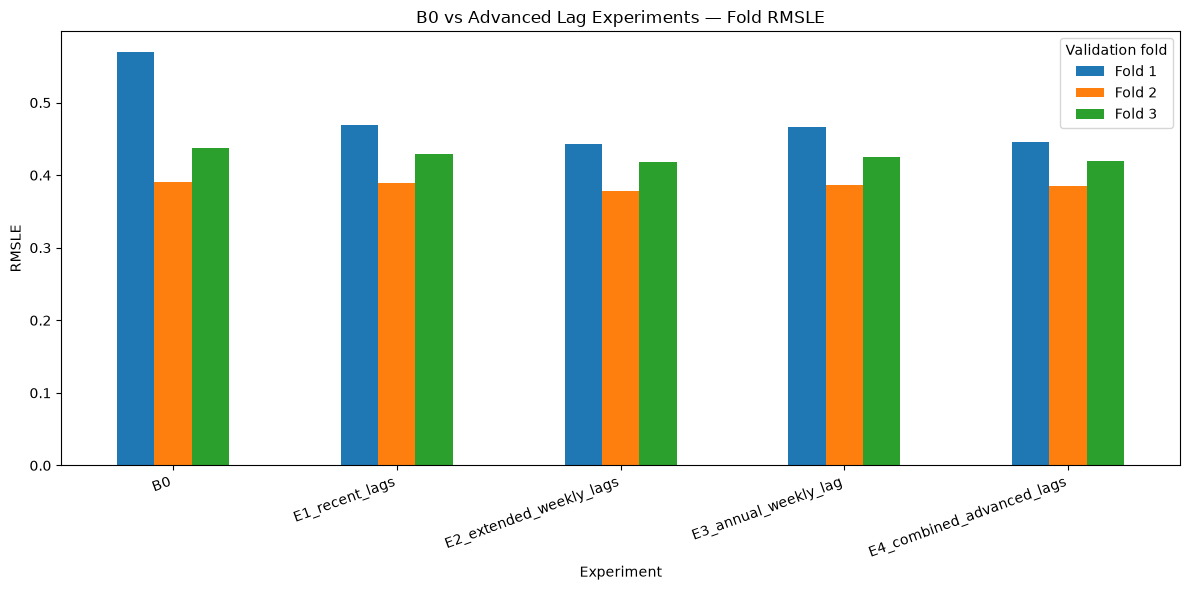

In [95]:
fold_comparison = stage2_results[
    ["experiment", *baseline_fold_cols]
].copy()

for fold_number, column in enumerate(baseline_fold_cols, start=1):
    baseline_score = float(
        baseline_row[column]
    )
    fold_comparison[f"fold_{fold_number}_improvement_pct"] = (
        (baseline_score - fold_comparison[column])
        / baseline_score * 100
    )

display(fold_comparison)

fold_comparison.to_csv(
    FEATURE_DIR / "stage_2_fold_comparison.csv",
    index=False
)

ax = (
    stage2_results
    .set_index("experiment")[baseline_fold_cols]
    .plot(kind="bar", figsize=(12, 6))
)

ax.set_title("B0 vs Advanced Lag Experiments — Fold RMSLE")
ax.set_xlabel("Experiment")
ax.set_ylabel("RMSLE")
ax.legend(["Fold 1", "Fold 2", "Fold 3"], title="Validation fold")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## Pooled OOF comparison

Pooled OOF RMSLE is the primary aggregate metric for this stage. The dashed reference line marks B0. Lower is better.


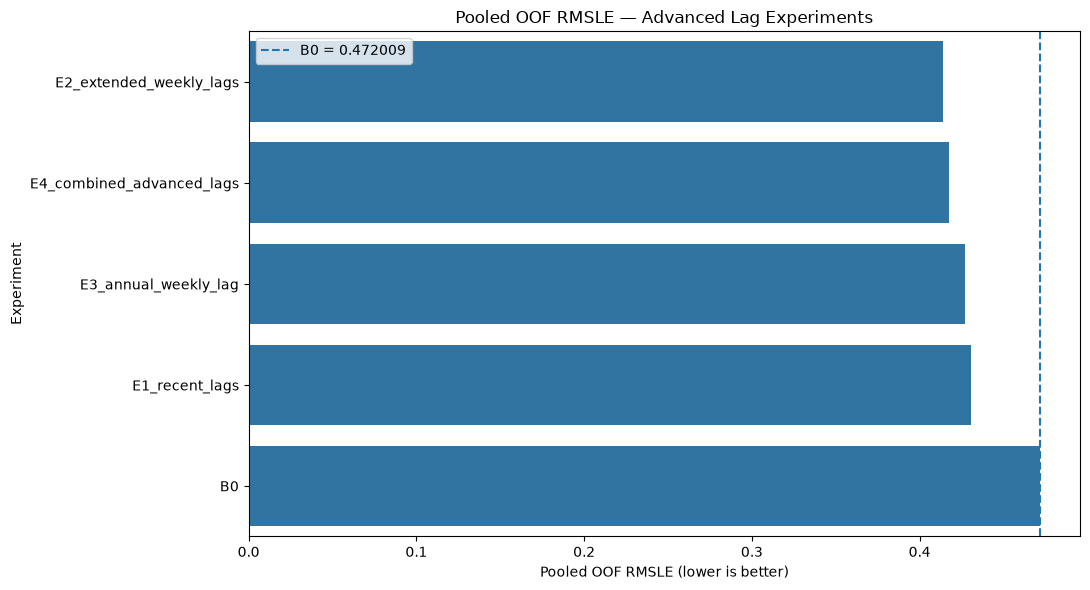

Best pooled-score candidate (not yet a final selection):
Experiment: E2_extended_weekly_lags
Pooled OOF RMSLE: 0.414153
Folds better than B0: 3 / 3
Improvement vs B0: 12.257 %


In [96]:
plot_results = stage2_results.sort_values(
    "pooled_oof_rmsle",
    ascending=True
).copy()

plt.figure(figsize=(11, 6))
sns.barplot(
    data=plot_results,
    x="pooled_oof_rmsle",
    y="experiment"
)
plt.axvline(
    baseline_pooled,
    linestyle="--",
    label=f"B0 = {baseline_pooled:.6f}"
)
plt.title("Pooled OOF RMSLE — Advanced Lag Experiments")
plt.xlabel("Pooled OOF RMSLE (lower is better)")
plt.ylabel("Experiment")
plt.legend()
plt.tight_layout()
plt.show()

candidate_rows = stage2_results.loc[
    stage2_results.experiment.ne("B0")
].sort_values("pooled_oof_rmsle")

candidate_best = candidate_rows.iloc[0]

print("Best pooled-score candidate (not yet a final selection):")
print("Experiment:", candidate_best.experiment)
print("Pooled OOF RMSLE:", round(candidate_best.pooled_oof_rmsle, 6))
print(
    "Folds better than B0:",
    int(candidate_best.folds_better_than_B0),
    "/ 3"
)
print(
    "Improvement vs B0:",
    round(candidate_best.improvement_pct_vs_B0, 3),
    "%"
)


## OOF integrity checks across experiments

Every experiment must produce the same validation keys and the same actual target values. This verifies that score differences are not caused by changed validation rows or different target alignment.


In [97]:
experiment_objects = {
    "E1_recent_lags": E1,
    "E2_extended_weekly_lags": E2,
    "E3_annual_weekly_lag": E3,
    "E4_combined_advanced_lags": E4,
}

oof_key_columns = [
    "fold", "date", "store_nbr", "family"
]

reference_oof = E1["oof_predictions"].sort_values(
    oof_key_columns
).reset_index(drop=True)

expected_oof_rows = len(FOLDS) * FOLD_DAYS * N_SERIES

assert len(reference_oof) == expected_oof_rows
assert not reference_oof.duplicated(oof_key_columns).any()

oof_integrity_rows = []

for experiment_name, result in experiment_objects.items():
    current = result["oof_predictions"].sort_values(
        oof_key_columns
    ).reset_index(drop=True)

    same_keys = current[oof_key_columns].equals(
        reference_oof[oof_key_columns]
    )
    same_actuals = np.allclose(
        current["sales_true"].to_numpy(),
        reference_oof["sales_true"].to_numpy(),
        rtol=0,
        atol=0,
    )
    unique_keys = not current.duplicated(oof_key_columns).any()
    correct_count = len(current) == expected_oof_rows
    nonnegative_finite_predictions = (
        np.isfinite(current["sales_pred"]).all()
        and current["sales_pred"].ge(0).all()
    )

    oof_integrity_rows.append({
        "experiment": experiment_name,
        "row_count_correct": correct_count,
        "keys_match_E1": same_keys,
        "actuals_match_E1": same_actuals,
        "keys_unique": unique_keys,
        "predictions_finite_nonnegative": nonnegative_finite_predictions,
    })

oof_integrity = pd.DataFrame(oof_integrity_rows)
display(oof_integrity)

assert oof_integrity.drop(columns="experiment").all().all(), (
    "OOF integrity check failed. Inspect oof_integrity."
)

oof_integrity.to_csv(
    FEATURE_DIR / "stage_2_oof_integrity.csv",
    index=False
)

print("All E1-E4 OOF integrity checks passed.")


,experiment,row_count_correct,keys_match_E1,actuals_match_E1,keys_unique,predictions_finite_nonnegative
0,E1_recent_lags,True,True,True,True,True
1,E2_extended_weekly_lags,True,True,True,True,True
2,E3_annual_weekly_lag,True,True,True,True,True
3,E4_combined_advanced_lags,True,True,True,True,True


All E1-E4 OOF integrity checks passed.


## Advanced lag feature-importance comparison

Compare normalized gain shares for the added lag features. Gain share is descriptive; it does not establish causal importance and should be interpreted alongside validation ablation results.


In [98]:
advanced_lag_names = [
    f"lag_{lag}" for lag in ALL_CANDIDATE_EXTRA_LAGS
]

importance_tables = []

for experiment_name in [
    "E1_recent_lags",
    "E2_extended_weekly_lags",
    "E3_annual_weekly_lag",
    "E4_combined_advanced_lags",
]:
    importance_path = (
        FEATURE_IMPORTANCE_DIR / f"{experiment_name}_summary.csv"
    )

    if not importance_path.is_file():
        raise FileNotFoundError(importance_path)

    current_importance = pd.read_csv(importance_path)
    current_importance = current_importance.loc[
        current_importance.feature.isin(advanced_lag_names)
    ].copy()
    current_importance["experiment"] = experiment_name
    importance_tables.append(current_importance)

advanced_importance_comparison = pd.concat(
    importance_tables,
    ignore_index=True
)

display(
    advanced_importance_comparison.sort_values(
        ["experiment", "mean_gain_share"],
        ascending=[True, False]
    )
)

advanced_importance_comparison.to_csv(
    FEATURE_DIR / "stage_2_advanced_lag_importance.csv",
    index=False
)


,feature,mean_gain,mean_gain_share,std_gain_share,mean_split,experiment
0,lag_1,1.287067e+07,0.065841,0.005913,1335.000000,E1_recent_lags
1,lag_2,1.773632e+06,0.008999,0.000056,629.000000,E1_recent_lags
2,lag_3,1.845552e+05,0.000946,0.000137,322.666667,E1_recent_lags
3,lag_5,7.075577e+04,0.000363,0.000041,362.666667,E1_recent_lags
4,lag_42,9.080936e+05,0.004615,0.000062,600.333333,E2_extended_weekly_lags
5,lag_56,7.099943e+05,0.003614,0.000086,666.333333,E2_extended_weekly_lags
6,lag_35,2.297233e+05,0.001177,0.000109,392.000000,E2_extended_weekly_lags
7,lag_364,2.802473e+05,0.001415,0.000108,926.000000,E3_annual_weekly_lag
8,lag_1,2.030672e+07,0.104247,0.014242,1261.666667,E4_combined_advanced_lags
9,lag_2,8.087954e+05,0.004304,0.002323,547.666667,E4_combined_advanced_lags


# Stage 2 — Final Review Checkpoint

Do not automatically select every lag in E4.

Use the experiment summary to consider:
1. Pooled OOF RMSLE relative to B0.
2. Improvements across all three folds.
3. Family-level regressions, especially high-volume families.
4. Forecast-horizon performance.
5. Missing rates and normalized gain shares.
6. Whether the result is stable enough to justify the extra feature complexity.

The lowest pooled OOF score is a candidate, not an automatic final decision. Review the resulting notebook and reports before writing `stage_2_selected_lags.json`.

After review, proceed to Stage 3 — Rolling Statistics.
